# Retinotopy in strabismic amblyopia: amblyopic eye vs fellow eye vs controls

**Questions.** (1) Are the pRFs measured through the amblyopic eye (AE) different from those measured through the fellow eye (FE)? (2) Are the pRFs of either eye different from those of controls? (3) Does it depend on which eye dominates the cortex (ocular dominance, OD)?

**Starting point.** Schluppeck et al. (2025, Vision Research 236:108677) analysed the same participants in **V1** with a Gaussian pRF model: same pRF eccentricity / cortical magnification in AE, FE and controls, only a small, hemisphere-specific difference of pRF size, and reproducible eccentricity maps between the two eyes (map correlation ≈ 0.65). Here we extend to **8 visual areas**, with the CSS pRF fits of the PSC pipeline (the same fits as the OD analysis), **one simple measure per question**, and the OD.

**Simple choices (same as the OD analysis):**

- **Same vertices for both eyes.** A vertex is kept when the pRF fits of **both** eyes pass the prf_analysis filters (eccentricity, size, n, R², positive amplitude, fit p ≤ 0.05). The two eyes are therefore compared on exactly the same piece of cortex (no eye loses more vertices than the other).
- **One weight:** mean pRF R² of the two eyes, everywhere.
- **Controls:** no dominant eye; their left and right eyes are first compared with each other (expected: no difference), then averaged (**CTRL**) for the comparison with the amblyopes (as Schluppeck et al.).
- **Statistics:** one value per subject and ROI; amblyopes AE vs FE: paired Wilcoxon; AE vs CTRL and FE vs CTRL: Mann-Whitney; controls LE vs RE: paired Wilcoxon; all two-sided, FDR over the 8 ROIs for each comparison. Bars = median across subjects, error bars = 25-75 %, dots = subjects.

**Measures (one per question):**

| | measure | why |
|---|---|---|
| Fig. 1 | **pRF R²** of each eye (weighted median) | does each eye drive retinotopic responses as well? |
| Fig. 2 | **pRF position shift between the eyes** (median distance between the pRF centres of the two eyes, degrees) and **eccentricity-map correlation** between the eyes | are the maps of the two eyes the same? (map fidelity, as Schluppeck et al.) |
| Fig. 3 | **pRF size at 2° eccentricity** (weighted regression of size on eccentricity, per subject, eye and ROI) | are the pRFs larger through the AE? |
| Fig. 4 | **cortical magnification (pCM) at 2°** (weighted regression of log pCM on log eccentricity) | is the cortical magnification changed? |
| Fig. 5 | **AE − FE size difference at the same vertex**, in the vertices that prefer the FE vs those that prefer the AE (OD) | do the AE pRFs differ more where the AE does not dominate? |
| Supp. | CSS exponent n, raw vs effective size | why n differs between groups |

**pRF size = effective size σ/√n.** In the CSS model, the fitted σ is not the pRF size: the effective size is σ/√n (Kay et al. 2013; the fit is initialised with this convention). Since n differs between participants, σ alone would mix size and compression. The supplementary section shows both.

**Size and pCM at a fixed eccentricity.** A ROI median of size or pCM depends on how the vertices are spread in eccentricity, which may differ between eyes or groups. Regressing on eccentricity and reading the value at 2° compares like with like. Eccentricity range of the regressions: 0.5-6° (stimulated field; Schluppeck et al.: 16° × 12° display).

Data: prfmodel PSC CSS fits, task BarsBarsRingsWedges (4 runs per eye), ROIs `rois-group-mmp`, OD image of `make_od_img.py`. Vertex data cached locally (`Desktop/fig_od/prf_od_filter_cache/`, same cache as `prf_comparison_od_filter.ipynb`). Nothing is written in the data folders; figures go to `Desktop/fig_od` (prefix `retino_`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import numpy as np
import pandas as pd
from scipy import stats
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sys.path.insert(0, "{}/../utils".format(os.getcwd()))
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from plot_utils import plotly_template
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
vcache_dir = '{}/prf_od_filter_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
analysis_info = load_settings([os.path.join(base_dir, project_dir, f) for f in
                               ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])[0]
patients, controls = analysis_info['group-patient'], analysis_info['group-control']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_pcm = analysis_info['maps_names_pcm']
maps_names_css_od = analysis_info['maps_names_css_od']
roi_colors = analysis_info['roi_colors']

task = 'BarsBarsRingsWedges'
rois_method = 'rois-group-mmp'
rois = list(analysis_info[rois_method].keys())
rois_to_plot = 'roi_mmp'
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
fspec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}_hemi-{}_fmriprep_dct_psc_concat_{}.func.gii'

# Vertex filters (as the OD analysis), applied to each eye
ecc_th, size_th, n_th, rsqr_th = analysis_info['ecc_th'], analysis_info['size_th'], analysis_info['n_th'], analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']['psc']
stats_th = analysis_info['stats_th']
stats_col = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Regressions on eccentricity
ecc_fit_range = [0.5, 6]          # stimulated field (deg)
ref_ecc = 2                       # value read at this eccentricity (deg)
min_vertices = 20

participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e)[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)}
set_pycortex_config_file('{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir))

## Vertex data (local cache, shared with `prf_comparison_od_filter.ipynb`)

In [3]:
def source_files(subject):
    fns = {'od': [fspec.format(pp_dir, subject, subject, task, h, 'prf-css_od') for h in 'LR']}
    for e, eye in eyes.items():
        fns['deriv_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, 'prf-css_deriv') for h in 'LR']
        fns['stats_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, 'prf-css_stats') for h in 'LR']
        fns['pcm_' + e] = [fspec.format(pp_dir, subject, subject, task + eye, h, '{}_prf-css_pcm'.format(rois_method)) for h in 'LR']
    return fns


def load_subject(subject):
    """DataFrame of the ROI vertices of one subject (one row per vertex), from the local cache when up to date."""
    fns = source_files(subject)
    all_fns = [f for v in fns.values() for f in v]
    if not all(os.path.isfile(f) for f in all_fns):
        return None
    cache_fn = '{}/{}_prf-od-filter-cache.tsv.gz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(f) for f in all_fns)
    if os.path.isfile(cache_fn) and os.path.getmtime(cache_fn) >= src_mtime:
        return pd.read_csv(cache_fn, sep='\t')
    roi_masks = get_rois(subject=subject, surf_format='fsnative', rois_type=rois_method, mask=True, rois=None, hemis=None)
    od = load_surface_pycortex(L_fn=fns['od'][0], R_fn=fns['od'][1], return_hemi_len=True)
    n_l = od['len_L']
    label = np.full(od['data_concat'].shape[1], '', dtype=object)
    for roi in rois:
        label[roi_masks[roi]] = roi
    idx = np.where(label != '')[0]
    df = pd.DataFrame({'vertex': idx, 'hemi': np.where(idx < n_l, 'hemi-L', 'hemi-R'), rois_to_plot: label[idx],
                       'beta_L': od['data_concat'][maps_names_css_od.index('od_beta_le')][idx],
                       'beta_R': od['data_concat'][maps_names_css_od.index('od_beta_re')][idx]})
    for e in eyes:
        for kind, names in [('deriv', maps_names_css), ('stats', maps_names_css_stats), ('pcm', maps_names_pcm)]:
            mat = load_surface_pycortex(L_fn=fns['{}_{}'.format(kind, e)][0], R_fn=fns['{}_{}'.format(kind, e)][1])['data_concat']
            for i, name in enumerate(names):
                df['{}_{}'.format(name, e)] = mat[i][idx]
    df.to_csv(cache_fn, sep='\t', index=False)
    print('{}: read from the data disks, cached'.format(subject), end=' | ')
    return df


vertex_data = {}
for subject in patients + controls:
    d = load_subject(subject)
    if d is None:
        print('{}: files missing, skipped'.format(subject))
        continue
    vertex_data[subject] = d
print('{} amblyopes, {} controls loaded'.format(sum(s in patients for s in vertex_data), sum(s in controls for s in vertex_data)))

sub-21: files missing, skipped
12 amblyopes, 7 controls loaded


## Measures per subject and ROI

For each subject and ROI (vertices kept for **both** eyes, weight w = mean pRF R² of both eyes):

- **R²** of each eye: weighted median.
- **Effective pRF size** of each vertex and eye: σ/√n. **Size at 2°**: weighted linear regression of the effective size on eccentricity (each eye's own eccentricity, 0.5-6°), value at 2°.
- **pCM at 2°**: weighted linear regression of log10(pCM) on log10(eccentricity) (0.5-6°), value at 2° (mm of cortex per degree).
- **n**, raw σ at 2° (supplementary), % of vertices with n at the upper bound (≥ 0.99).
- **Between the eyes**: distance between the pRF centres of the two eyes at each vertex (degrees; weighted median) and the same distance divided by the mean effective size of the two eyes; weighted correlation of the eccentricity maps of the two eyes (vertices with both eccentricities ≤ 6°).
- **OD**: OD index of each vertex toward the FE-LE eye, `(β_FE − β_AE) / (β_FE + β_AE)` (both betas > 0). In the vertices preferring FE-LE (OD > 0) and in those preferring AE-RE (OD < 0): weighted median of the vertex difference AE − FE of effective size, and of the position shift. ROI OD index = weighted median of the vertex OD (as Figure 2 of the OD analysis).

Labels: amblyopes FE = fellow eye, AE = amblyopic eye; controls FE = left eye (LE), AE = right eye (RE).

In [4]:
def select(d, e):
    """prf_analysis filters of one eye (as the OD analysis)."""
    g = lambda k: d['{}_{}'.format(k, e)]
    return ((g('prf_ecc') >= ecc_th[0]) & (g('prf_ecc') <= ecc_th[1]) & (g('prf_size') >= size_th[0]) & (g('prf_size') <= size_th[1])
            & (g('prf_n') >= n_th[0]) & (g('prf_n') <= n_th[1]) & (g('prf_rsq') >= rsqr_th)
            & (g('amplitude') > 0) & (g('amplitude') <= amp_th[1]) & (g(stats_col) <= stats_th))


def wmedian(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok]); cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def wcorr(x, y, w):
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def wls_at(x, y, w, x0):
    """Weighted linear regression y = a + b x; returns (value at x0, slope)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    if ok.sum() < min_vertices:
        return np.nan, np.nan
    x, y, w = x[ok], y[ok], w[ok]
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    b = np.sum(w * (x - mx) * (y - my)) / np.sum(w * (x - mx) ** 2)
    return my + b * (x0 - mx), b


rows = []
for subject, d in vertex_data.items():
    group = 'patient' if subject in patients else 'control'
    fe, ae = ('R', 'L') if (group == 'patient' and ambly_eye[subject] == 'L') else ('L', 'R')
    keep = select(d, 'L') & select(d, 'R')
    w_all = ((d.prf_rsq_L + d.prf_rsq_R) / 2).clip(lower=0).values
    eff = {e: (d['prf_size_' + e] / np.sqrt(d['prf_n_' + e])).values for e in eyes}
    b_fe, b_ae = d['beta_' + fe].values, d['beta_' + ae].values
    with np.errstate(divide='ignore', invalid='ignore'):
        od = np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)
    shift = np.hypot(d.prf_x_L - d.prf_x_R, d.prf_y_L - d.prf_y_R).values
    shift_rel = shift / ((eff['L'] + eff['R']) / 2)
    for roi in rois:
        m = keep.values & (d[rois_to_plot] == roi).values
        if m.sum() < min_vertices:
            continue
        w = w_all[m]
        row = {'subject': subject, 'group': group, 'roi': roi, 'n_vertices': int(m.sum()),
               'shift_deg': wmedian(shift[m], w), 'shift_rel': wmedian(shift_rel[m], w),
               'od_index': wmedian(od[m], w)}
        both_in = m & (d.prf_ecc_L <= ecc_fit_range[1]).values & (d.prf_ecc_R <= ecc_fit_range[1]).values
        row['ecc_corr'] = wcorr(d.prf_ecc_L[both_in], d.prf_ecc_R[both_in], w_all[both_in])
        for lab, e in [('FE', fe), ('AE', ae)]:
            ecc = d['prf_ecc_' + e].values
            inr = m & (ecc >= ecc_fit_range[0]) & (ecc <= ecc_fit_range[1])
            row['rsq_' + lab] = wmedian(d['prf_rsq_' + e].values[m], w)
            row['size_' + lab], row['size_slope_' + lab] = wls_at(ecc[inr], eff[e][inr], w_all[inr], ref_ecc)
            row['sigma_' + lab], _ = wls_at(ecc[inr], d['prf_size_' + e].values[inr], w_all[inr], ref_ecc)
            pcm = d['pcm_median_' + e].values
            okp = inr & (pcm > 0)
            lp, _ = wls_at(np.log10(ecc[okp]), np.log10(pcm[okp]), w_all[okp], np.log10(ref_ecc))
            row['pcm_' + lab] = 10 ** lp
            row['n_' + lab] = wmedian(d['prf_n_' + e].values[m], w)
            row['n_bound_' + lab] = 100 * np.sum(w * (d['prf_n_' + e].values[m] >= 0.99)) / np.sum(w)
        # OD split: AE - FE vertex differences in the vertices preferring each eye
        for side, sel in [('FEpref', od > 0), ('AEpref', od < 0)]:
            ms = m & sel
            row['n_' + side] = int(ms.sum())
            ok_e = ms & (d['prf_ecc_' + fe].values <= ecc_fit_range[1]) & (d['prf_ecc_' + ae].values <= ecc_fit_range[1])
            row['dsize_' + side] = wmedian(eff[ae][ok_e] - eff[fe][ok_e], w_all[ok_e]) if ok_e.sum() >= min_vertices else np.nan
            row['shift_' + side] = wmedian(shift[ms], w_all[ms]) if ms.sum() >= min_vertices else np.nan
        rows.append(row)
df = pd.DataFrame(rows)
for meas in ['rsq', 'size', 'sigma', 'pcm', 'n', 'n_bound', 'size_slope']:
    df[meas + '_CTRL'] = np.where(df.group == 'control', (df[meas + '_FE'] + df[meas + '_AE']) / 2, np.nan)
print(df.groupby(['group', 'roi']).n_vertices.median().unstack('group').reindex(rois).to_string())

group  control  patient
roi                    
V1      5197.0   4320.5
V2      4749.0   4117.5
V3      3215.0   2960.0
V4      2716.0   2454.5
V3A      756.0   1000.5
V3B      315.0    509.0
LO1      523.0    429.0
LO2      509.0    292.0


## Statistics and figure functions

In [5]:
def bh_fdr(p):
    p = np.asarray(p, float); out = np.full(p.shape, np.nan); ok = np.isfinite(p)
    if ok.sum():
        q = p[ok]; o = np.argsort(q); r = q[o] * ok.sum() / (np.arange(ok.sum()) + 1)
        r = np.minimum(np.minimum.accumulate(r[::-1])[::-1], 1); t = np.empty_like(r); t[o] = r; out[ok] = t
    return out


def stars(p):
    return '' if not np.isfinite(p) else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def wilcoxon_p(a, b=None):
    a = np.asarray(a, float) if b is None else np.asarray(a, float) - np.asarray(b, float)
    a = a[np.isfinite(a)]
    return stats.wilcoxon(a).pvalue if len(a) > 1 and np.any(a != 0) else np.nan


def mwu_p(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    return stats.mannwhitneyu(a, b, alternative='two-sided').pvalue if len(a) > 1 and len(b) > 1 else np.nan


def eye_tests(meas):
    """Per ROI: amblyopes AE vs FE (paired), AE vs CTRL, FE vs CTRL (Mann-Whitney), controls LE vs RE (paired); FDR over ROIs."""
    rows = []
    for roi in rois:
        p, c = df[(df.roi == roi) & (df.group == 'patient')], df[(df.roi == roi) & (df.group == 'control')]
        rows.append({'roi': roi, 'AE': p[meas + '_AE'].median(), 'FE': p[meas + '_FE'].median(), 'CTRL': c[meas + '_CTRL'].median(),
                     'LE': c[meas + '_FE'].median(), 'RE': c[meas + '_AE'].median(),
                     'p_AE_FE': wilcoxon_p(p[meas + '_AE'], p[meas + '_FE']),
                     'p_AE_CTRL': mwu_p(p[meas + '_AE'], c[meas + '_CTRL']),
                     'p_FE_CTRL': mwu_p(p[meas + '_FE'], c[meas + '_CTRL']),
                     'p_LE_RE': wilcoxon_p(c[meas + '_FE'], c[meas + '_AE'])})
    s = pd.DataFrame(rows).set_index('roi')
    for col in ['p_AE_FE', 'p_AE_CTRL', 'p_FE_CTRL', 'p_LE_RE']:
        s[col + '_fdr'] = bh_fdr(s[col])
    return s


def group_tests(meas):
    """Per ROI: amblyopes vs controls (Mann-Whitney), FDR over ROIs."""
    rows = []
    for roi in rois:
        p, c = df[(df.roi == roi) & (df.group == 'patient')][meas], df[(df.roi == roi) & (df.group == 'control')][meas]
        rows.append({'roi': roi, 'amblyopes': p.median(), 'controls': c.median(), 'p': mwu_p(p, c)})
    s = pd.DataFrame(rows).set_index('roi'); s['p_fdr'] = bh_fdr(s.p)
    return s


template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15, bg_col="rgba(255, 255, 255, 1)",
                      font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
ctrl_color = 'rgb(150,150,150)'
rng = np.random.default_rng(0)


def bar_panel(conds, star_pairs, y_title, fn_out, y_range=None):
    """2 x 4 ROI panels. conds: list of (label, column, group, colour or None for the ROI colour, pattern).
    star_pairs: list of (index_a, index_b, p column of the stats table, stats table) drawn as a bracket with stars."""
    fig = make_subplots(rows=2, cols=4, subplot_titles=rois, horizontal_spacing=0.06, vertical_spacing=0.16)
    allv = np.concatenate([df[df.group == g][col].dropna().values for _, col, g, _, _ in conds])
    lo, hi = (min(0, np.nanpercentile(allv, 1)), np.nanpercentile(allv, 99)) if y_range is None else y_range
    span = hi - lo
    for k, roi in enumerate(rois):
        r_i, c_i = k // 4 + 1, k % 4 + 1
        for x_i, (lab, col, g, colr, pat) in enumerate(conds):
            v = df[(df.roi == roi) & (df.group == g)][col].dropna()
            if len(v) == 0:
                continue
            med, p25, p75 = v.median(), v.quantile(0.25), v.quantile(0.75)
            fig.add_trace(go.Bar(x=[x_i], y=[med], width=0.7, showlegend=False,
                                 marker=dict(color=roi_colors[roi] if colr is None else colr,
                                             pattern=dict(shape=pat, fgcolor='black', bgcolor='rgba(0,0,0,0)', size=7)),
                                 error_y=dict(type='data', array=[p75 - med], arrayminus=[med - p25], thickness=2, width=0, color='black')),
                          row=r_i, col=c_i)
            fig.add_trace(go.Scatter(x=x_i + rng.uniform(-0.2, 0.2, len(v)), y=v, mode='markers', showlegend=False,
                                     marker=dict(size=4, color='rgba(0,0,0,0.55)')), row=r_i, col=c_i)
        level = hi - 0.02 * span
        for a, b, pcol, s in star_pairs:
            st = stars(s.loc[roi, pcol])
            if st:
                fig.add_shape(type='line', x0=a, x1=b, y0=level, y1=level, line=dict(color='black', width=1.2), row=r_i, col=c_i)
                fig.add_annotation(x=(a + b) / 2, y=level, text=st, showarrow=False, yanchor='bottom', font=dict(size=14), row=r_i, col=c_i)
            level -= 0.08 * span
        fig.update_xaxes(tickvals=list(range(len(conds))), ticktext=[c[0] for c in conds], row=r_i, col=c_i)
        fig.update_yaxes(range=[lo, hi + 0.05 * span], row=r_i, col=c_i)
    fig.update_yaxes(title_text=y_title, col=1)
    fig.update_layout(template=fig_template, height=760, width=1150, margin=dict(l=90, r=30, t=60, b=50))
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


three = lambda m: [('AE', m + '_AE', 'patient', None, '/'), ('FE', m + '_FE', 'patient', None, ''), ('CTRL', m + '_CTRL', 'control', ctrl_color, '')]


def three_stars(s):
    return [(0, 1, 'p_AE_FE_fdr', s), (0, 2, 'p_AE_CTRL_fdr', s), (1, 2, 'p_FE_CTRL_fdr', s)]


pd.set_option('display.width', 250)
show = lambda s: print(s.round(3).to_string())

## Figure 1 — Does each eye drive retinotopic responses as well? (pRF R²)

Weighted median pRF R² of each eye, on the vertices kept for both eyes. AE (hatched) and FE (solid) of the amblyopes, CTRL (mean of the two eyes of the controls, grey). Brackets: AE vs FE, AE vs CTRL, FE vs CTRL (FDR over the 8 ROIs). Table: controls LE vs RE (expected: no difference).

        AE     FE   CTRL     LE     RE  p_AE_FE  p_AE_CTRL  p_FE_CTRL  p_LE_RE  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
roi                                                                                                                                   
V1   0.442  0.467  0.378  0.395  0.361    0.092      0.967      0.650    0.578        0.092          0.967            1.0        0.786
V2   0.365  0.404  0.396  0.435  0.358    0.034      0.482      0.837    0.469        0.046          0.772            1.0        0.786
V3   0.294  0.387  0.314  0.351  0.285    0.005      0.432      0.384    0.578        0.010          0.772            1.0        0.786
V4   0.230  0.310  0.333  0.330  0.292    0.005      0.340      0.711    0.688        0.010          0.772            1.0        0.786
V3A  0.235  0.395  0.260  0.262  0.258    0.001      0.711      0.482    0.812        0.006          0.948            1.0        0.812
V3B  0.190  0.237  0.185  0.171  0.198    0.064      0.

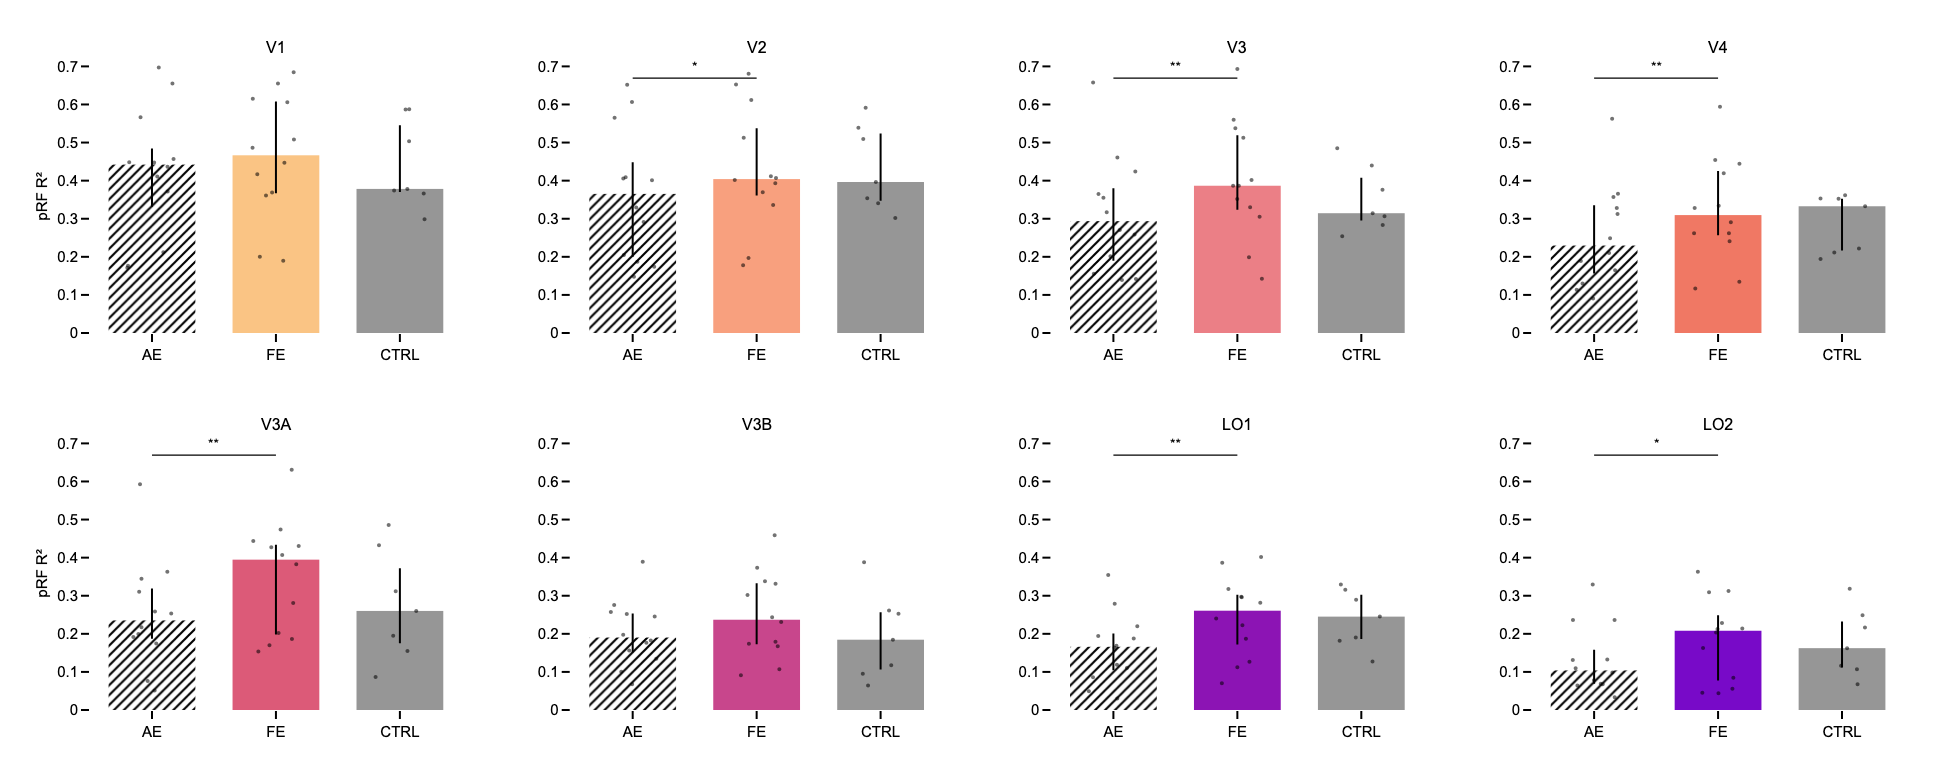

In [6]:
s_rsq = eye_tests('rsq')
show(s_rsq)
bar_panel(three('rsq'), three_stars(s_rsq), 'pRF R²', 'retino_fig1_rsq')

## Figure 2 — Are the maps of the two eyes the same? (map fidelity)

For each vertex, distance between the pRF centre measured through one eye and through the other eye. Left: in degrees; right: relative to the pRF size (1 = shifted by one pRF size). Amblyopes vs controls (Mann-Whitney, FDR). Controls give the value expected from noise alone (two independent fits of the same eye-independent map). Table: also the correlation of the eccentricity maps of the two eyes (Schluppeck et al.: ≈ 0.65 in V1).


pRF shift between the eyes (deg)
     amblyopes  controls      p  p_fdr
roi                                   
V1       0.646     0.380  0.100  0.134
V2       0.651     0.416  0.056  0.089
V3       0.889     0.342  0.028  0.057
V4       0.884     0.460  0.017  0.046
V3A      1.208     0.743  0.261  0.261
V3B      1.108     0.451  0.013  0.046
LO1      0.829     0.528  0.142  0.163
LO2      0.872     0.500  0.013  0.046


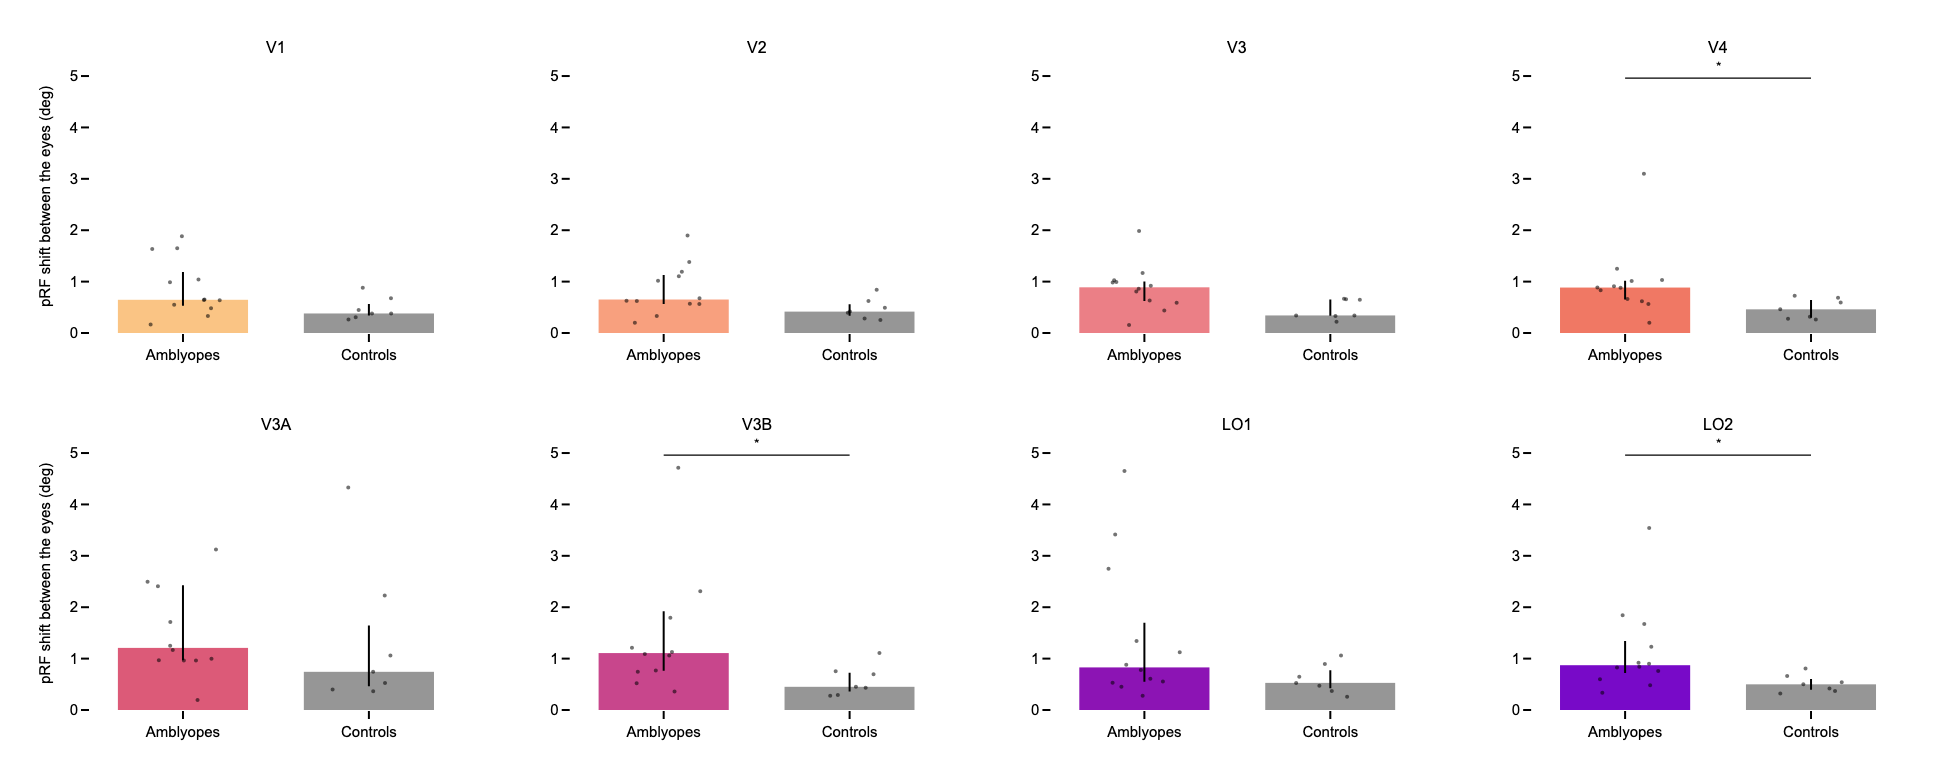


pRF shift between the eyes (pRF sizes)
     amblyopes  controls      p  p_fdr
roi                                   
V1       0.916     0.530  0.083  0.222
V2       0.848     0.544  0.068  0.222
V3       0.761     0.621  0.068  0.222
V4       0.580     0.447  0.340  0.680
V3A      0.670     0.597  0.837  0.957
V3B      0.540     0.632  0.967  0.967
LO1      0.708     0.550  0.536  0.857
LO2      0.690     0.680  0.650  0.867


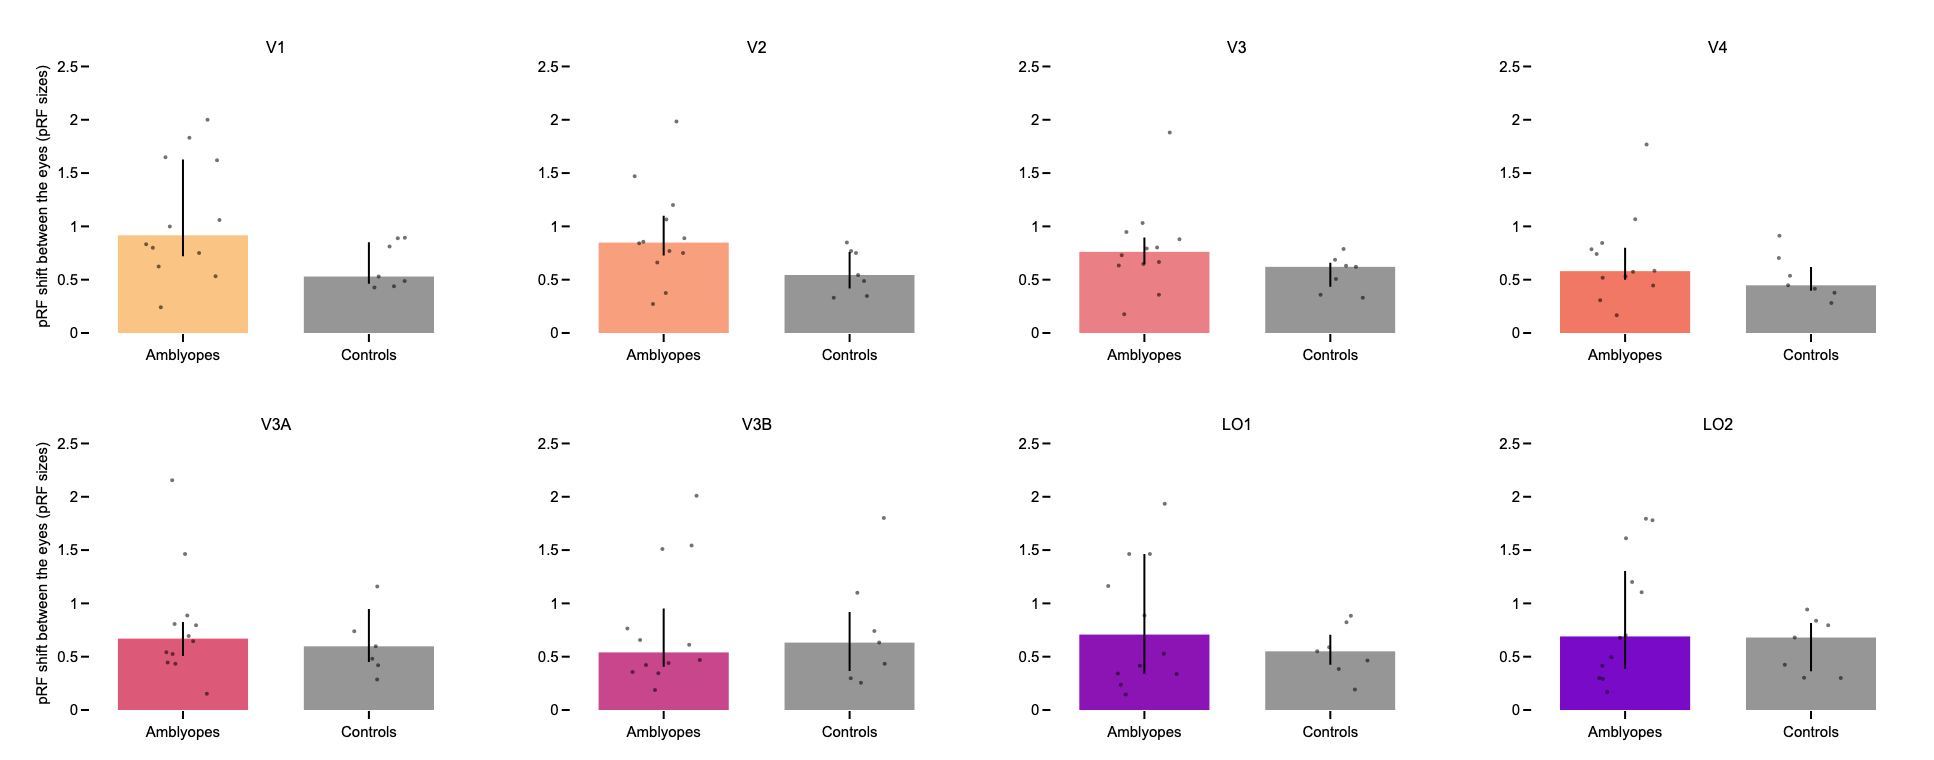


eccentricity-map correlation between the eyes
     amblyopes  controls      p  p_fdr
roi                                   
V1       0.844     0.873  0.902  1.000
V2       0.780     0.904  0.227  0.363
V3       0.782     0.903  0.196  0.363
V4       0.705     0.883  0.120  0.363
V3A      0.638     0.866  0.167  0.363
V3B      0.742     0.851  0.167  0.363
LO1      0.327     0.641  0.592  0.789
LO2      0.593     0.522  1.000  1.000


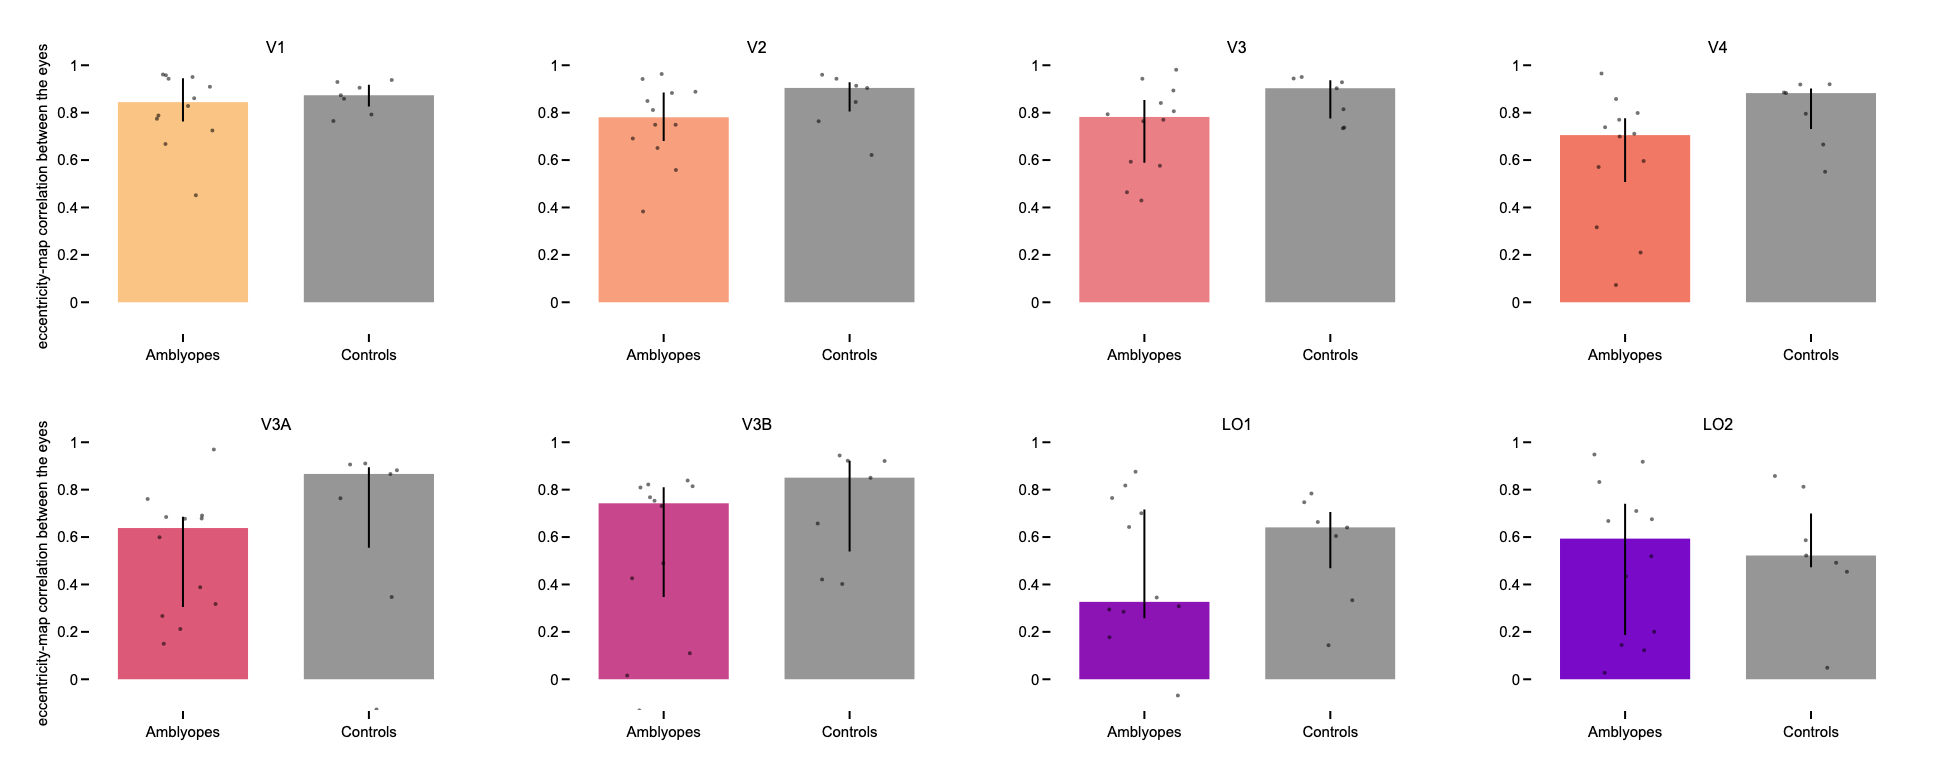

In [7]:
for meas, lab in [('shift_deg', 'pRF shift between the eyes (deg)'), ('shift_rel', 'pRF shift between the eyes (pRF sizes)'),
                   ('ecc_corr', 'eccentricity-map correlation between the eyes')]:
    s = group_tests(meas)
    print('\n' + lab); show(s)
    bar_panel([('Amblyopes', meas, 'patient', None, ''), ('Controls', meas, 'control', ctrl_color, '')], [(0, 1, 'p_fdr', s)], lab,
              'retino_fig2_{}'.format(meas))

## Figure 3 — Are the pRFs larger through the amblyopic eye? (effective pRF size at 2°)

Effective size σ/√n at 2° eccentricity, from the weighted regression of size on eccentricity (0.5-6°) of each subject, eye and ROI. Same layout as Figure 1. The table also gives the slope of the size-eccentricity relation.

        AE     FE   CTRL     LE     RE  p_AE_FE  p_AE_CTRL  p_FE_CTRL  p_LE_RE  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
roi                                                                                                                                   
V1   0.820  0.677  0.811  0.850  0.779    0.034      0.967      0.045    0.469        0.091          0.967          0.332        0.925
V2   1.005  0.838  0.913  0.919  0.901    0.077      0.227      0.650    0.812        0.103          0.302          0.967        0.938
V3   1.445  1.064  1.042  1.066  1.065    0.012      0.120      0.967    0.578        0.091          0.192          0.967        0.925
V4   2.164  1.514  1.373  1.366  1.380    0.064      0.045      0.340    0.938        0.102          0.111          0.680        0.938
V3A  2.227  1.954  1.423  1.639  1.204    0.052      0.028      0.196    0.578        0.102          0.111          0.521        0.925
V3B  2.753  2.096  1.619  1.494  1.743    0.129      0.

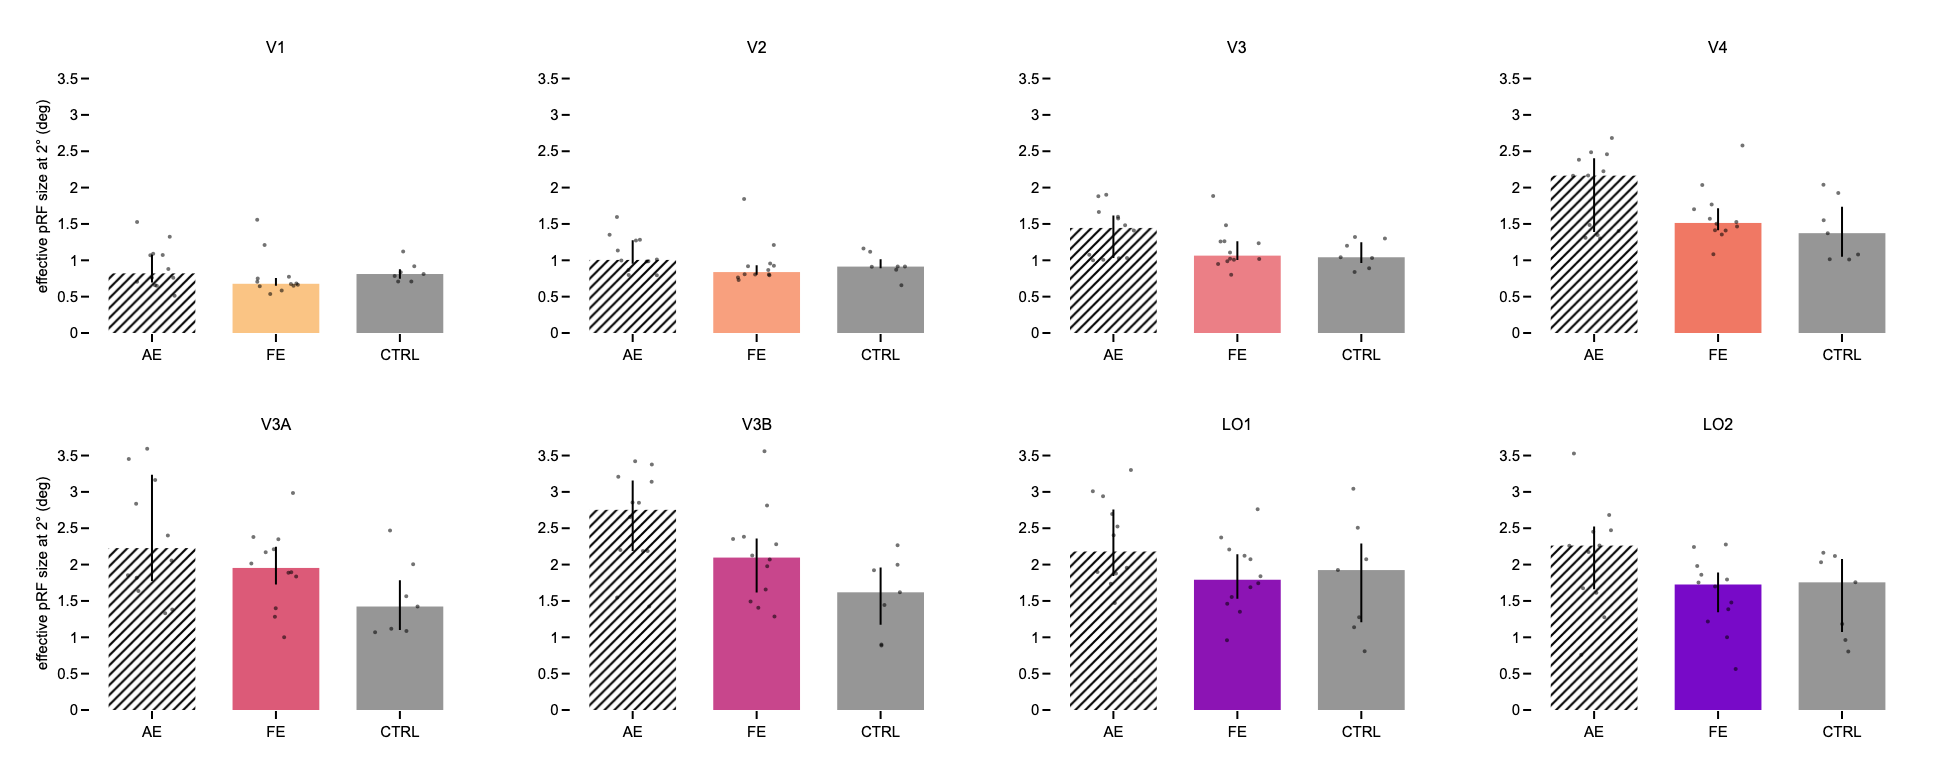

In [8]:
s_size = eye_tests('size')
show(s_size)
print('\nSlope of size vs eccentricity'); show(eye_tests('size_slope'))
bar_panel(three('size'), three_stars(s_size), 'effective pRF size at {}° (deg)'.format(ref_ecc), 'retino_fig3_size')

## Figure 4 — Is the cortical magnification changed? (pCM at 2°)

pCM at 2° (mm of cortex per degree), from the weighted regression of log pCM on log eccentricity (0.5-6°). Same layout as Figure 1.

        AE     FE   CTRL     LE     RE  p_AE_FE  p_AE_CTRL  p_FE_CTRL  p_LE_RE  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
roi                                                                                                                                   
V1   7.215  7.355  7.704  8.373  7.093    0.519      0.384      0.536    0.156        0.830          0.812          0.711        0.625
V2   7.919  7.881  7.270  7.193  7.379    0.519      0.902      0.432    0.812        0.830          0.902          0.711        0.938
V3   8.729  8.432  8.169  7.996  8.336    0.850      0.650      0.711    0.688        0.850          0.812          0.711        0.938
V4   7.680  8.096  7.981  8.038  7.924    0.791      0.536      0.650    0.938        0.850          0.812          0.711        0.938
V3A  4.928  5.510  4.090  4.643  3.536    0.110      0.592      0.167    0.031        0.293          0.812          0.605        0.250
V3B  4.265  5.335  3.712  3.766  3.860    0.027      0.

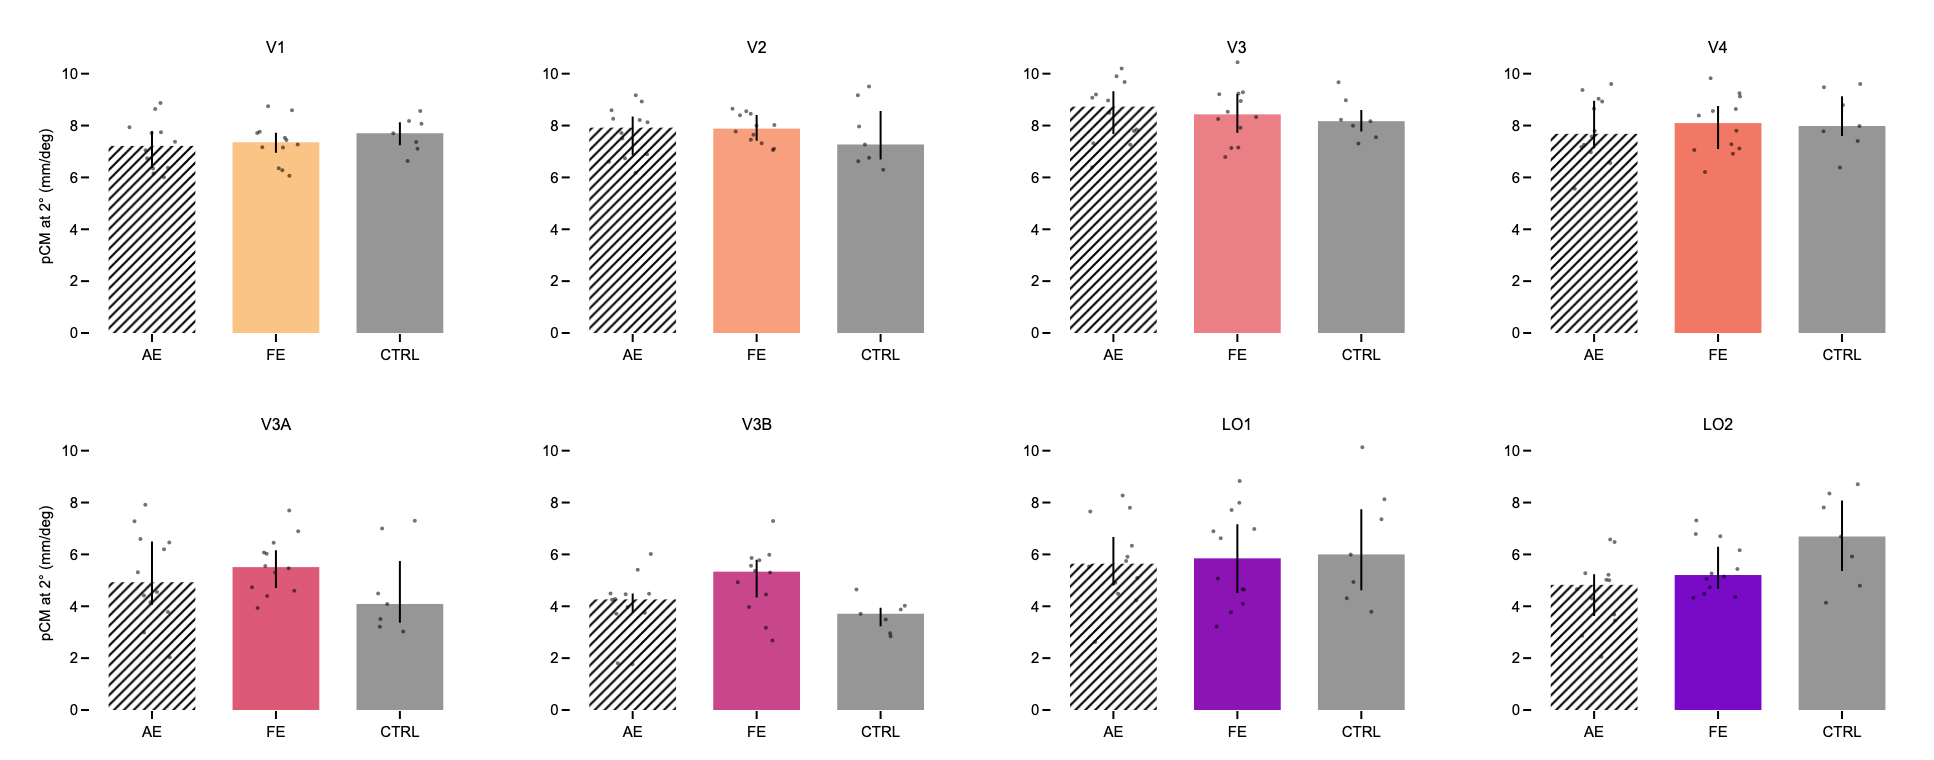

In [9]:
s_pcm = eye_tests('pcm')
show(s_pcm)
bar_panel(three('pcm'), three_stars(s_pcm), 'pCM at {}° (mm/deg)'.format(ref_ecc), 'retino_fig4_pcm')

## Figure 5 — Ocular dominance: do the AE pRFs differ more where the AE does not dominate?

At each vertex, difference of effective pRF size AE − FE (same vertex, both pRFs within 0.5-6°), weighted median over the vertices preferring the FE (OD > 0, solid) and over those preferring the AE (OD < 0, hatched). Controls: RE − LE in the vertices preferring LE / RE. 0 = same size through both eyes. Tests: each bar vs 0 (Wilcoxon) and FE-preferring vs AE-preferring (paired Wilcoxon), FDR over the ROIs.

**Caveat.** The OD and the pRFs come from the same runs. A vertex where the AE response is weak is more likely to prefer the FE **and** to have a noisier AE pRF: part of a difference between the two subsets can come from this. The pRF R² is not split by OD for this reason (a vertex preferring an eye has, by construction, a stronger response to it). The table also gives the position shift between the eyes in each subset, and the correlation across amblyopes between the ROI OD index and the AE − FE differences.

             dsize_FEpref  dsize_AEpref  p_FEpref_vs0  p_AEpref_vs0  p_FEpref_vs_AEpref  shift_FEpref  shift_AEpref  p_shift  n_FEpref  n_AEpref  p_FEpref_vs0_fdr  p_AEpref_vs0_fdr  p_FEpref_vs_AEpref_fdr  p_shift_fdr
group   roi                                                                                                                                                                                                              
patient V1          0.079         0.175         0.092         0.002               0.003         0.661         0.722    0.850    2630.5    1993.0             0.246             0.020                   0.027        0.966
control V1          0.056         0.028         0.297         0.156               0.297         0.411         0.379    0.078    3156.0    2009.0             0.536             0.938                   0.938        0.292
patient V2          0.061         0.186         0.151         0.012               0.009         0.774         0.922    0.339    

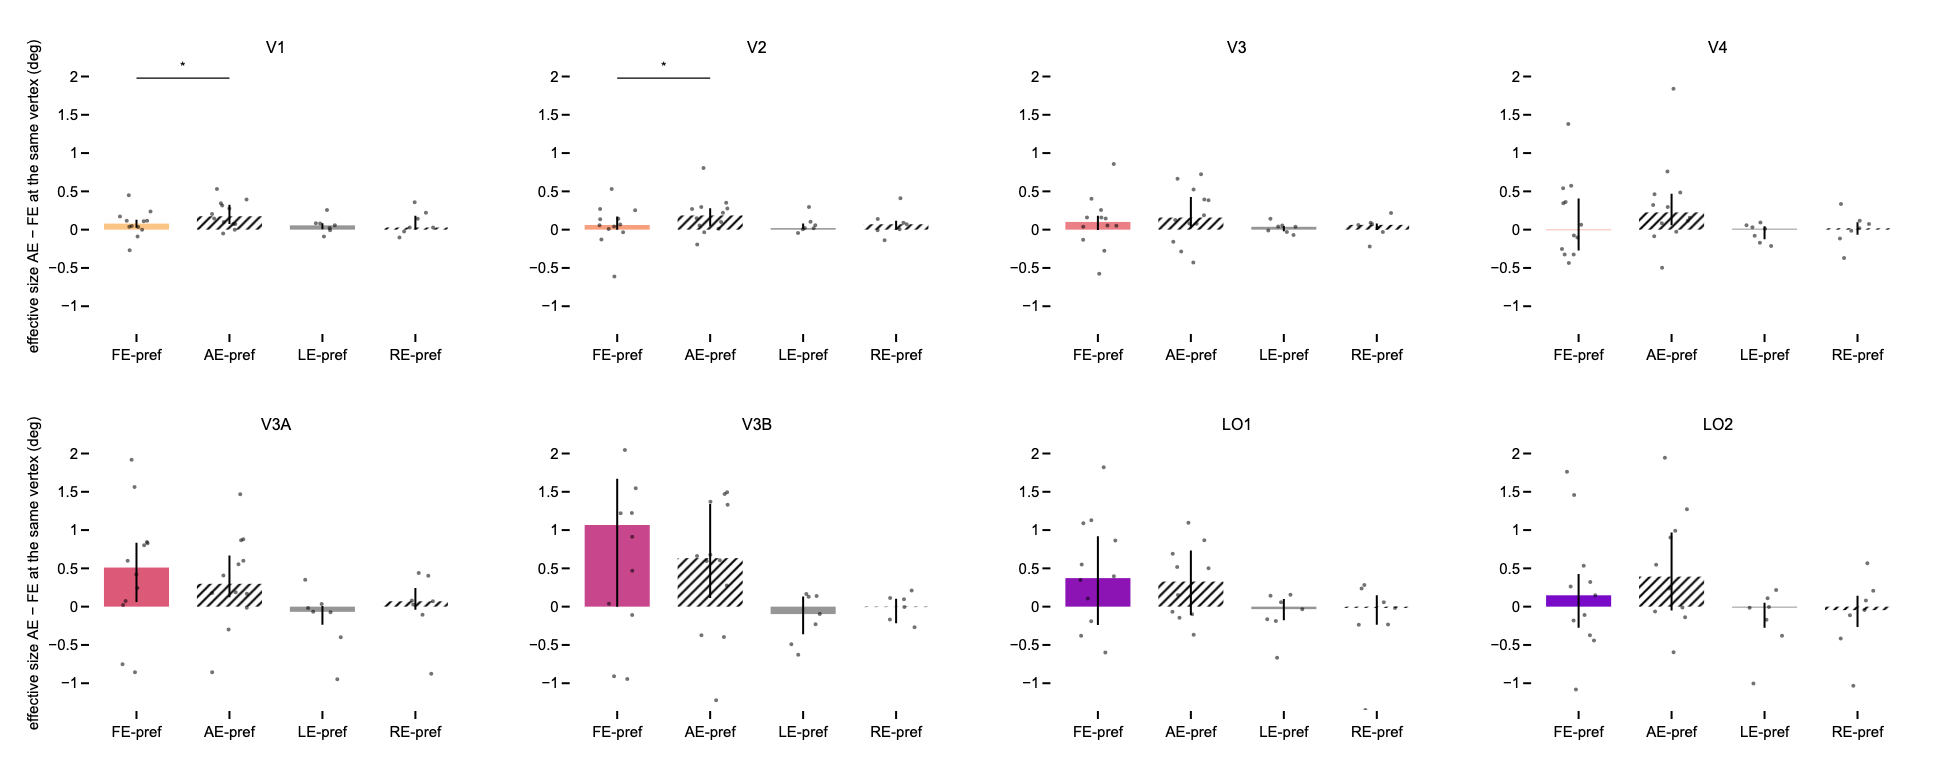


Amblyopes, Spearman across subjects: ROI OD index vs AE − FE R², AE − FE size at 2°, relative pRF shift (uncorrected)
     rho_OD_d_rsq  p_d_rsq  rho_OD_d_size  p_d_size  rho_OD_shift_rel  p_shift_rel
roi                                                                               
V1         -0.385    0.217          0.469     0.124            -0.322        0.308
V2         -0.573    0.051          0.476     0.118             0.119        0.713
V3         -0.692    0.013          0.636     0.026             0.196        0.542
V4         -0.797    0.002          0.441     0.152             0.469        0.124
V3A        -0.657    0.020          0.399     0.199             0.469        0.124
V3B        -0.944    0.000          0.406     0.191             0.084        0.795
LO1        -0.832    0.001         -0.287     0.366             0.308        0.331
LO2        -0.916    0.000         -0.315     0.319             0.196        0.542


In [10]:
rows = []
for roi in rois:
    for g in ['patient', 'control']:
        d = df[(df.roi == roi) & (df.group == g)]
        rows.append({'roi': roi, 'group': g, 'dsize_FEpref': d.dsize_FEpref.median(), 'dsize_AEpref': d.dsize_AEpref.median(),
                     'p_FEpref_vs0': wilcoxon_p(d.dsize_FEpref), 'p_AEpref_vs0': wilcoxon_p(d.dsize_AEpref),
                     'p_FEpref_vs_AEpref': wilcoxon_p(d.dsize_FEpref, d.dsize_AEpref),
                     'shift_FEpref': d.shift_FEpref.median(), 'shift_AEpref': d.shift_AEpref.median(),
                     'p_shift': wilcoxon_p(d.shift_FEpref, d.shift_AEpref),
                     'n_FEpref': d.n_FEpref.median(), 'n_AEpref': d.n_AEpref.median()})
s_od = pd.DataFrame(rows)
for col in ['p_FEpref_vs0', 'p_AEpref_vs0', 'p_FEpref_vs_AEpref', 'p_shift']:
    s_od[col + '_fdr'] = s_od.groupby('group')[col].transform(lambda p: bh_fdr(p.values))
s_od = s_od.set_index(['group', 'roi'])
show(s_od)

# figure: amblyopes and controls, size difference in each OD subset
s_star = s_od.loc['patient']
fig_conds = [('FE-pref', 'dsize_FEpref', 'patient', None, ''), ('AE-pref', 'dsize_AEpref', 'patient', None, '/'),
             ('LE-pref', 'dsize_FEpref', 'control', ctrl_color, ''), ('RE-pref', 'dsize_AEpref', 'control', ctrl_color, '/')]
bar_panel(fig_conds, [(0, 1, 'p_FEpref_vs_AEpref_fdr', s_star)], 'effective size AE − FE at the same vertex (deg)', 'retino_fig5_od_size')

# across amblyopes: ROI OD index vs AE - FE differences
pat = df[df.group == 'patient'].copy()
pat['d_rsq'], pat['d_size'] = pat.rsq_AE - pat.rsq_FE, pat.size_AE - pat.size_FE
rows = []
for roi in rois:
    d = pat[pat.roi == roi]
    r = {'roi': roi}
    for meas in ['d_rsq', 'd_size', 'shift_rel']:
        ok = d[['od_index', meas]].dropna()
        rho, p = stats.spearmanr(ok.od_index, ok[meas]) if len(ok) > 3 else (np.nan, np.nan)
        r['rho_OD_' + meas], r['p_' + meas] = rho, p
    rows.append(r)
print('\nAmblyopes, Spearman across subjects: ROI OD index vs AE − FE R², AE − FE size at 2°, relative pRF shift (uncorrected)')
show(pd.DataFrame(rows).set_index('roi'))

## Supplementary — CSS exponent n and raw σ

- **n**: weighted median of the CSS exponent of each eye; % of the weight with n at the upper bound of the fit (n ≥ 0.99, i.e. no compression). The fit bounds n to [0.01, 1]; vertices stuck at the bound suggest that the optimiser did not move n.
- **Raw σ at 2°** vs **effective size at 2°**: if n differs between groups, a group difference of raw σ can disappear (or appear) with the effective size.


CSS exponent n (weighted median)
        AE     FE   CTRL     LE     RE  p_AE_FE  p_AE_CTRL  p_FE_CTRL  p_LE_RE  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
roi                                                                                                                                   
V1   0.636  0.589  0.925  0.850  0.999    0.850      0.142      0.068    0.938        0.910          0.454          0.494        0.938
V2   0.548  0.431  0.713  0.705  0.722    0.622      0.711      0.536    0.469        0.903          0.711          0.536        0.938
V3   0.480  0.333  0.644  0.600  0.696    0.470      0.227      0.167    0.938        0.903          0.454          0.494        0.938
V4   0.264  0.227  0.652  0.644  0.700    0.677      0.340      0.384    0.812        0.903          0.454          0.494        0.938
V3A  0.218  0.194  0.461  0.276  0.645    0.910      0.261      0.432    0.109        0.910          0.454          0.494        0.583
V3B  0.133  0.144  0.

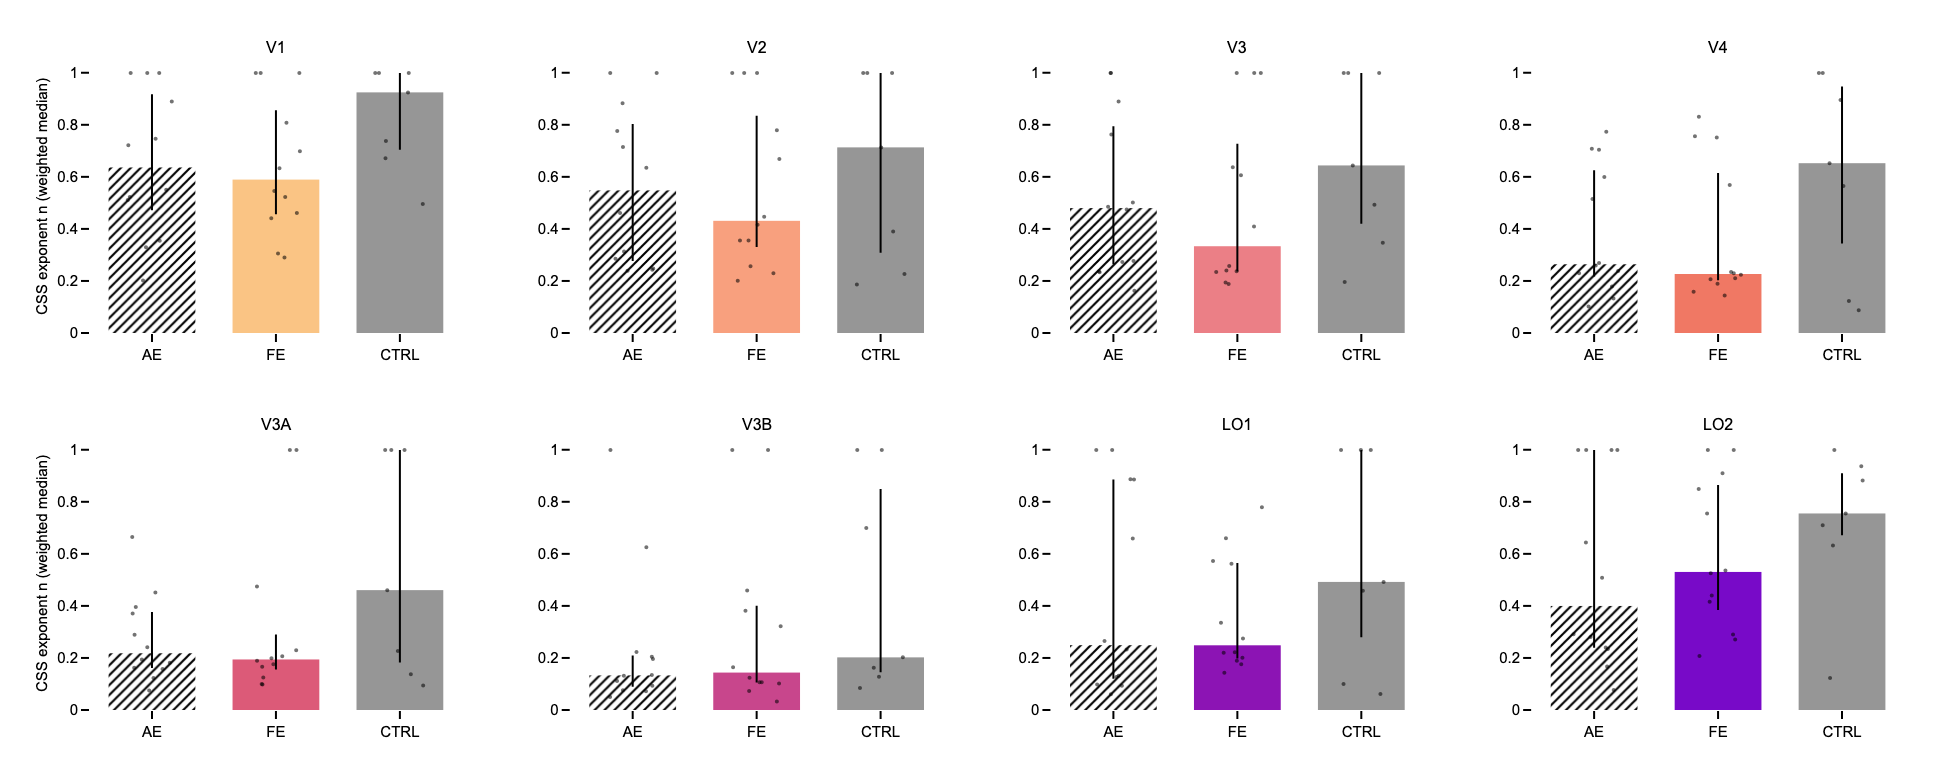


% of the weight with n >= 0.99
         AE      FE    CTRL      LE      RE  p_AE_FE  p_AE_CTRL  p_FE_CTRL  p_LE_RE  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
roi                                                                                                                                        
V1   32.021  32.707  49.760  46.347  56.237    0.910      0.056      0.068    0.812        0.910          0.240          0.223        0.938
V2   32.958  31.039  40.265  38.153  42.376    0.850      0.227      0.299    0.938        0.910          0.363          0.342        0.938
V3   22.299  28.731  35.451  30.958  39.944    0.733      0.120      0.167    0.938        0.910          0.240          0.223        0.938
V4   19.009  19.496  35.507  31.853  39.161    0.266      0.083      0.142    0.812        0.803          0.240          0.223        0.938
V3A  13.107   8.780  37.807  38.028  37.587    0.850      0.100      0.083    0.297        0.910          0.240          0.223  

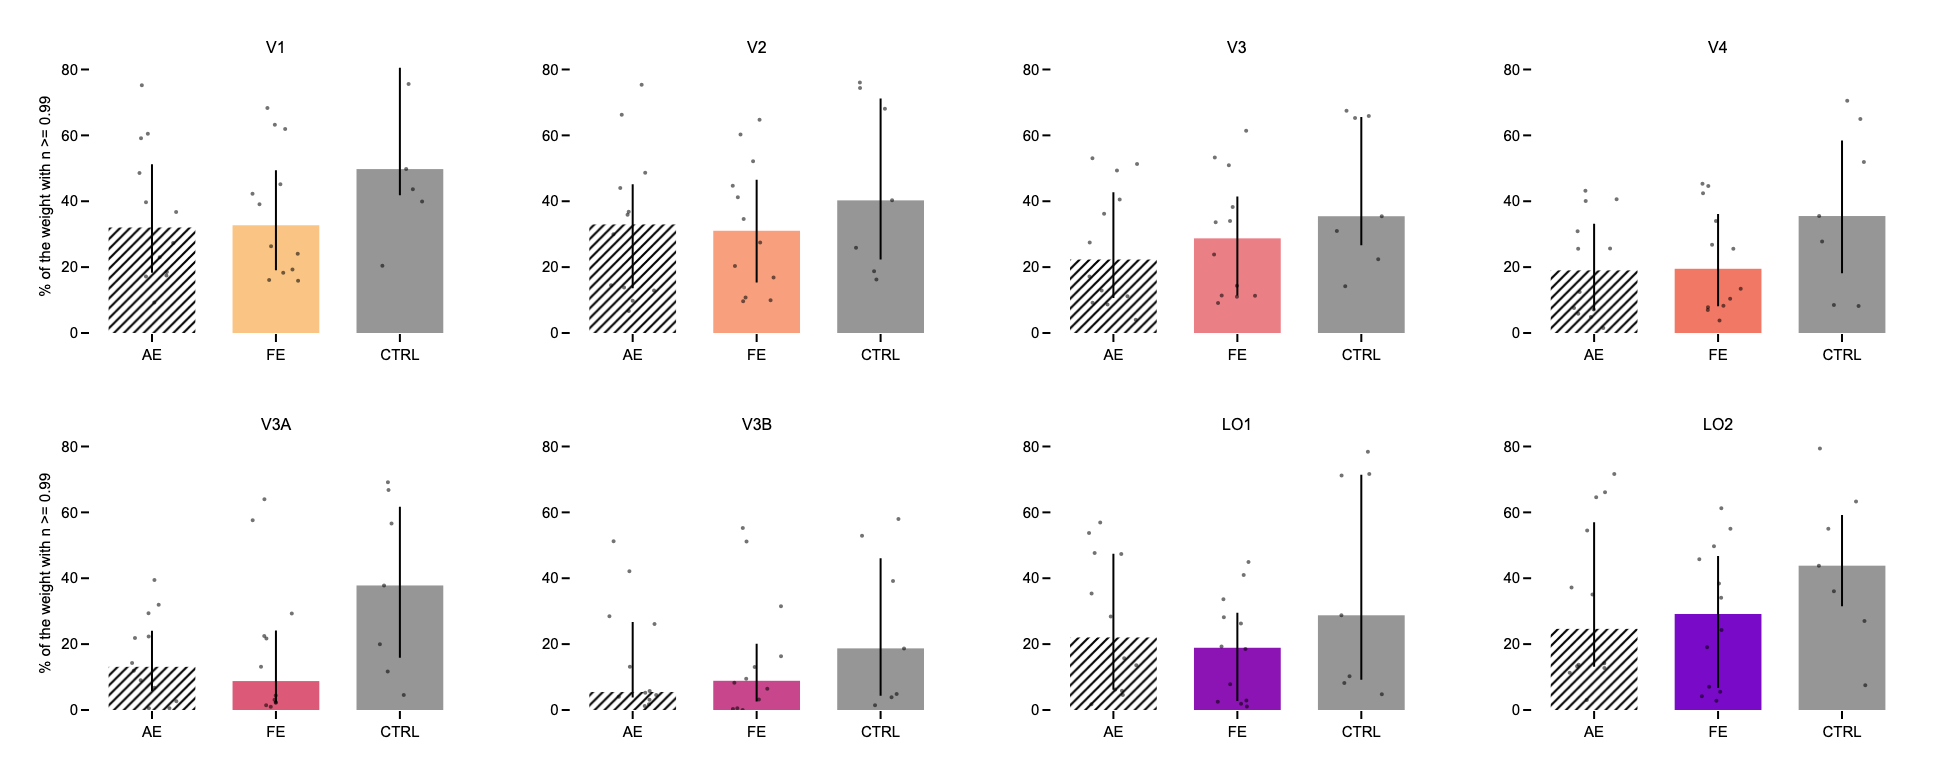


raw sigma at 2 deg
        AE     FE   CTRL     LE     RE  p_AE_FE  p_AE_CTRL  p_FE_CTRL  p_LE_RE  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
roi                                                                                                                                   
V1   0.544  0.468  0.685  0.688  0.681    0.005      0.384      0.045    0.375        0.027          0.691          0.359        0.786
V2   0.714  0.510  0.844  0.688  0.844    0.027      0.967      0.650    0.688        0.054          0.967          0.957        0.786
V3   0.778  0.605  0.733  0.676  0.790    0.052      0.432      0.299    0.469        0.084          0.691          0.957        0.786
V4   0.893  0.765  0.792  0.751  0.830    0.021      0.100      0.773    0.812        0.054          0.379          0.957        0.812
V3A  0.856  0.761  0.874  0.789  0.975    0.380      0.837      0.837    0.688        0.435          0.957          0.957        0.786
V3B  0.933  0.716  0.695  0.709  0.

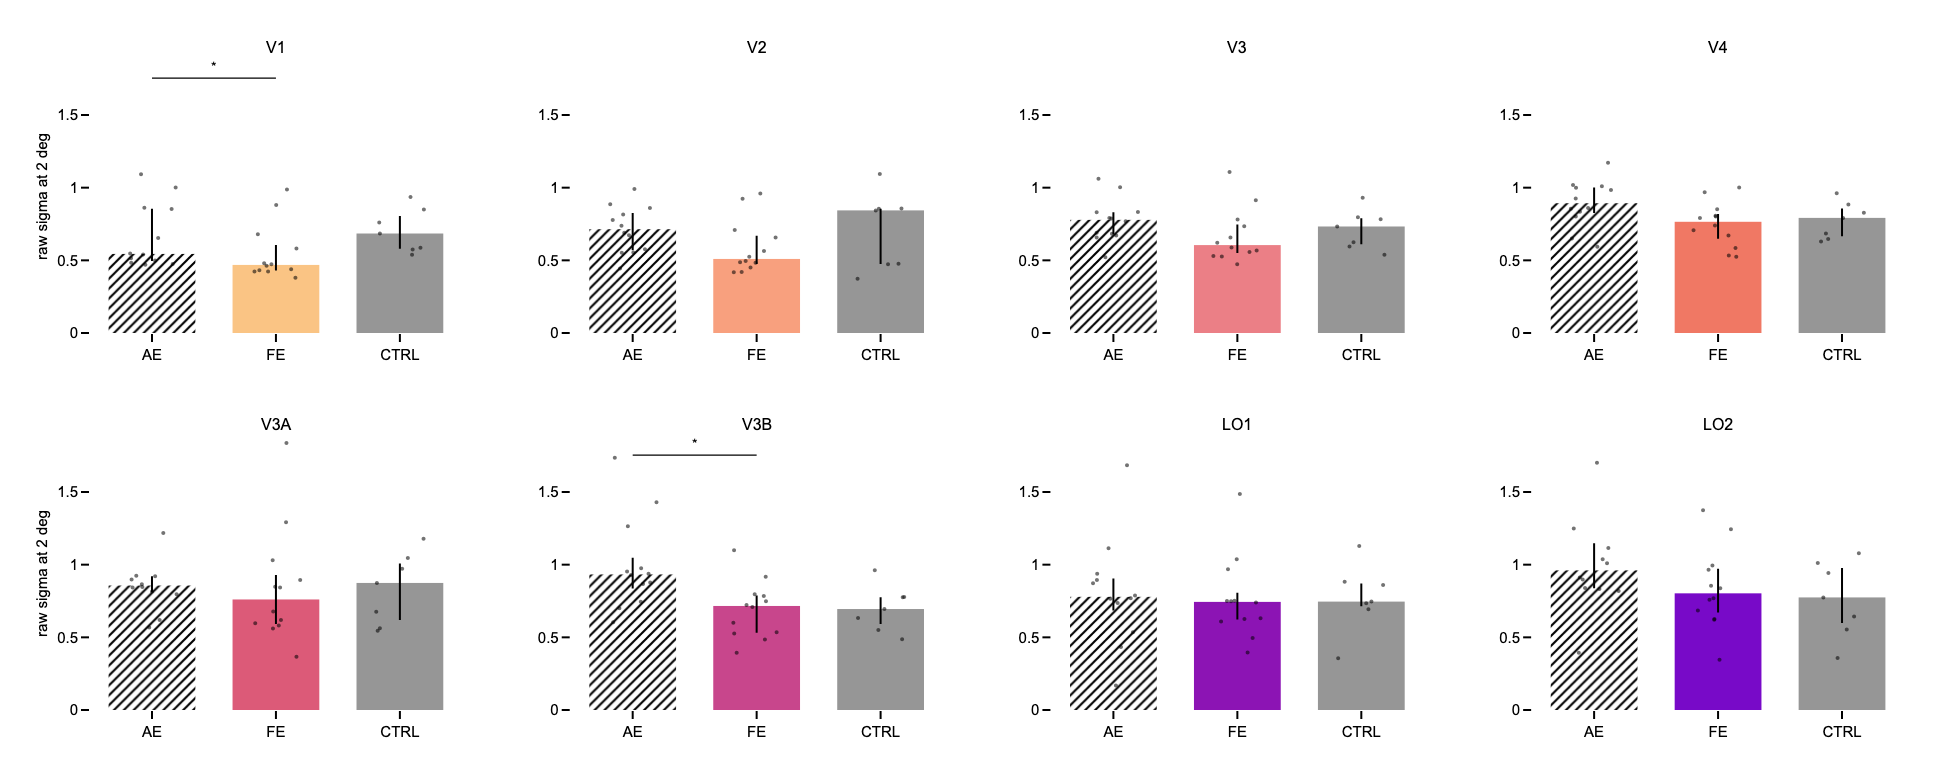


Per subject, median over V1-V3
                 n_FE  n_AE  n_bound_FE  n_bound_AE  rsq_FE  rsq_AE
group   subject                                                    
control sub-13   0.28  0.17       24.61        7.83    0.44    0.58
        sub-14   1.00  1.00       77.03       71.69    0.35    0.33
        sub-16   1.00  1.00       64.94       83.49    0.38    0.21
        sub-17   1.00  1.00       68.42       67.87    0.37    0.34
        sub-18   0.29  0.70       23.20       38.66    0.53    0.47
        sub-19   0.70  0.72       38.15       42.38    0.40    0.36
        sub-20   0.37  0.32       24.61       20.13    0.56    0.62
patient sub-01   0.23  0.24       10.75       12.94    0.68    0.66
        sub-02   0.36  0.31       16.85        6.71    0.61    0.57
        sub-03   0.29  0.50       23.81       27.47    0.51    0.36
        sub-04   0.67  0.72       41.21       39.72    0.18    0.15
        sub-05   0.20  0.71       10.98       35.93    0.37    0.41
        sub-06  

In [11]:
for meas, lab in [('n', 'CSS exponent n (weighted median)'), ('n_bound', '% of the weight with n >= 0.99'), ('sigma', 'raw sigma at 2 deg')]:
    s = eye_tests(meas)
    print('\n' + lab); show(s)
    bar_panel(three(meas), three_stars(s), lab, 'retino_supp_{}'.format(meas))

# per subject: median n over V1-V3 (is a group difference driven by a few subjects?)
early = df[df.roi.isin(['V1', 'V2', 'V3'])]
per_subj = early.groupby(['group', 'subject'])[['n_FE', 'n_AE', 'n_bound_FE', 'n_bound_AE', 'rsq_FE', 'rsq_AE']].median().round(2)
print('\nPer subject, median over V1-V3'); print(per_subj.to_string())
print('\nAcross subjects and eyes (V1-V3 medians): Spearman n vs R² = {:.2f} (p = {:.3f})'.format(
    *stats.spearmanr(np.r_[per_subj.n_FE, per_subj.n_AE], np.r_[per_subj.rsq_FE, per_subj.rsq_AE])))

## Summary table

For each measure and ROI: medians (AE, FE, CTRL) and FDR-corrected p of AE vs FE, AE vs CTRL, FE vs CTRL; controls LE vs RE.

In [12]:
summary = []
for meas, s in [('R²', s_rsq), ('size at 2°', s_size), ('pCM at 2°', s_pcm)]:
    t = s[['AE', 'FE', 'CTRL', 'p_AE_FE_fdr', 'p_AE_CTRL_fdr', 'p_FE_CTRL_fdr', 'p_LE_RE_fdr']].copy()
    t.insert(0, 'measure', meas)
    summary.append(t.reset_index())
summary = pd.concat(summary, ignore_index=True)
print(summary.round(3).to_string(index=False))

roi    measure    AE    FE  CTRL  p_AE_FE_fdr  p_AE_CTRL_fdr  p_FE_CTRL_fdr  p_LE_RE_fdr
 V1         R² 0.442 0.467 0.378        0.092          0.967          1.000        0.786
 V2         R² 0.365 0.404 0.396        0.046          0.772          1.000        0.786
 V3         R² 0.294 0.387 0.314        0.010          0.772          1.000        0.786
 V4         R² 0.230 0.310 0.333        0.010          0.772          1.000        0.786
V3A         R² 0.235 0.395 0.260        0.006          0.948          1.000        0.812
V3B         R² 0.190 0.237 0.185        0.073          0.957          1.000        0.786
LO1         R² 0.166 0.261 0.245        0.006          0.665          1.000        0.625
LO2         R² 0.104 0.208 0.162        0.046          0.772          1.000        0.786
 V1 size at 2° 0.820 0.677 0.811        0.091          0.967          0.332        0.925
 V2 size at 2° 1.005 0.838 0.913        0.103          0.302          0.967        0.938
 V3 size at 2° 1.445 